DATASET INFORMATION
Dataset Shape: (569, 33)

First 5 rows:
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

  

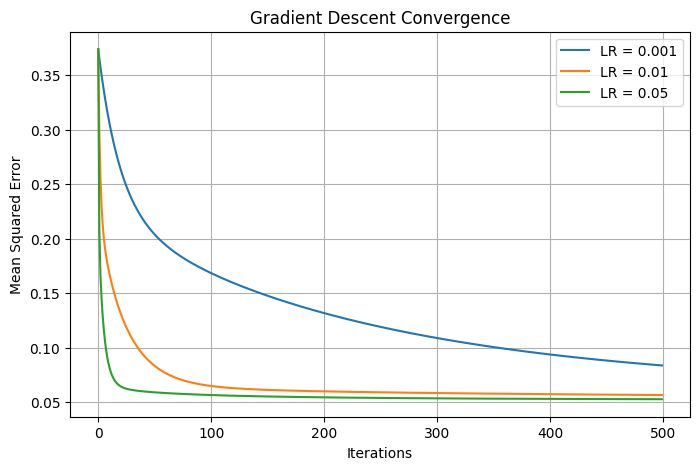


LINEAR REGRESSION RESULTS
         Feature Set  Features      MSE     RMSE      MAE       R2
            Original        30 0.062653 0.250306 0.201047 0.730741
        Low Variance        30 0.062653 0.250306 0.201047 0.730741
    High Correlation        20 0.066416 0.257713 0.208167 0.714569
     Factor Analysis        10 0.071546 0.267481 0.217817 0.692521
Backward Elimination        15 0.061178 0.247342 0.200776 0.737080
   Forward Selection        15 0.060215 0.245388 0.200818 0.741218

LOGISTIC REGRESSION

LOGISTIC REGRESSION RESULTS
         Feature Set  Features  Accuracy  Precision   Recall  F1 Score
            Original        30  0.964912    0.97500 0.928571  0.951220
        Low Variance        30  0.964912    0.97500 0.928571  0.951220
    High Correlation        20  0.973684    1.00000 0.928571  0.962963
     Factor Analysis        10  0.973684    1.00000 0.928571  0.962963
Backward Elimination        15  0.982456    1.00000 0.952381  0.975610
   Forward Selection        

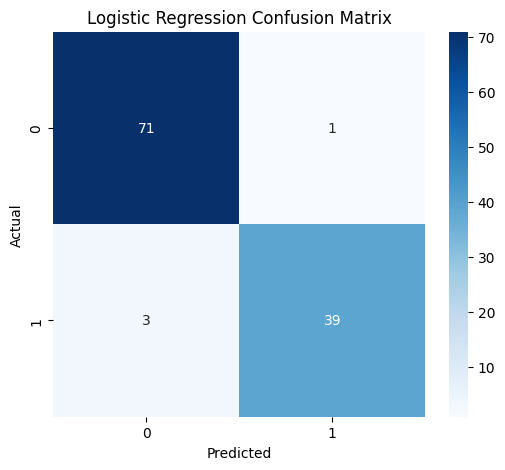


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


K-FOLD CROSS VALIDATION
            Feature Set  Mean CV R2  Std CV R2
0              Original    0.727388   0.016393
1          Low Variance    0.727388   0.016393
2      High Correlation    0.701940   0.046122
3       Factor Analysis    0.715808   0.030096
4  Backward Elimination    0.751896   0.030797
5     Forward Selection    0.742698   0.026227

LOGISTIC REGRESSION CV
            Feature Set  Mean CV Accuracy  Std CV Accuracy
0              Original          0.973626         0.014906
1          Low Variance          0.973626         0.014906
2      High Correlation          0.973626         0.008791
3       Factor Analysis          0.

In [2]:


import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore")


import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.feature_selection import (
    SequentialFeatureSelector,
    VarianceThreshold
)


from sklearn.decomposition import FactorAnalysis


from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



df = pd.read_csv("Cancer Prediction Dataset.csv")

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


columns_to_drop = []

for col in df.columns:
    if col.lower() in ["id", "unnamed: 32"]:
        columns_to_drop.append(col)

if columns_to_drop:
    df = df.drop(columns=columns_to_drop)



if df["diagnosis"].dtype == "object":
    df["diagnosis"] = df["diagnosis"].map({
        "M": 1,
        "B": 0
    })


X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]


X = X.apply(pd.to_numeric, errors="coerce")


imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("\nNumber of Instances:", X.shape[0])
print("Number of Features:", X.shape[1])

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Proportion:")
print(y.value_counts(normalize=True))


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)



scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nScaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)




print("\n" + "=" * 70)
print("LOW VARIANCE FILTER")
print("=" * 70)

variance_selector = VarianceThreshold(
    threshold=0.01
)

variance_selector.fit(X_train_scaled)

variance_features = X_train_scaled.columns[
    variance_selector.get_support()
].tolist()

print("Original Features:", X_train_scaled.shape[1])
print("Features Retained:", len(variance_features))

print("\nRetained Features:")
print(variance_features)

X_train_variance = X_train_scaled[variance_features]
X_test_variance = X_test_scaled[variance_features]




print("\n" + "=" * 70)
print("HIGH CORRELATION FILTER")
print("=" * 70)

correlation_matrix = X_train_scaled.corr().abs()

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

correlated_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.90)
]

correlation_features = [
    feature
    for feature in X_train_scaled.columns
    if feature not in correlated_features
]

print("Original Features:", X_train_scaled.shape[1])
print("Removed Features:", len(correlated_features))
print("Features Retained:", len(correlation_features))

print("\nRemoved Features:")
print(correlated_features)

print("\nRetained Features:")
print(correlation_features)

X_train_corr = X_train_scaled[correlation_features]
X_test_corr = X_test_scaled[correlation_features]


print("\n" + "=" * 70)
print("FACTOR ANALYSIS")
print("=" * 70)


n_factors = min(10, X_train_scaled.shape[1])

factor_model = FactorAnalysis(
    n_components=n_factors,
    random_state=42
)

X_train_factor = factor_model.fit_transform(
    X_train_scaled
)

X_test_factor = factor_model.transform(
    X_test_scaled
)

factor_columns = [
    "Factor_" + str(i + 1)
    for i in range(n_factors)
]

X_train_factor = pd.DataFrame(
    X_train_factor,
    columns=factor_columns,
    index=X_train_scaled.index
)

X_test_factor = pd.DataFrame(
    X_test_factor,
    columns=factor_columns,
    index=X_test_scaled.index
)

print("Original Features:", X_train_scaled.shape[1])
print("Factors Retained:", n_factors)
print("Factors:", factor_columns)


print("\n" + "=" * 70)
print("BACKWARD FEATURE ELIMINATION")
print("=" * 70)

linear_model = LinearRegression()

backward_selector = SequentialFeatureSelector(
    linear_model,
    n_features_to_select=15,
    direction="backward",
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

backward_selector.fit(
    X_train_scaled,
    y_train
)

backward_features = X_train_scaled.columns[
    backward_selector.get_support()
].tolist()

print("Original Features:", X_train_scaled.shape[1])
print("Features Retained:", len(backward_features))

print("\nSelected Features:")
print(backward_features)

X_train_backward = X_train_scaled[backward_features]
X_test_backward = X_test_scaled[backward_features]




print("\n" + "=" * 70)
print("FORWARD FEATURE SELECTION")
print("=" * 70)

forward_selector = SequentialFeatureSelector(
    linear_model,
    n_features_to_select=15,
    direction="forward",
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)

forward_selector.fit(
    X_train_scaled,
    y_train
)

forward_features = X_train_scaled.columns[
    forward_selector.get_support()
].tolist()

print("Original Features:", X_train_scaled.shape[1])
print("Features Retained:", len(forward_features))

print("\nSelected Features:")
print(forward_features)

X_train_forward = X_train_scaled[forward_features]
X_test_forward = X_test_scaled[forward_features]




feature_summary = pd.DataFrame({
    "Technique": [
        "Original",
        "Low Variance",
        "High Correlation",
        "Factor Analysis",
        "Backward Elimination",
        "Forward Selection"
    ],
    "Number of Features": [
        X_train_scaled.shape[1],
        len(variance_features),
        len(correlation_features),
        n_factors,
        len(backward_features),
        len(forward_features)
    ]
})

print("\n" + "=" * 70)
print("FEATURE SELECTION SUMMARY")
print("=" * 70)

print(feature_summary)



print("\n" + "=" * 70)
print("GRADIENT DESCENT – LINEAR REGRESSION")
print("=" * 70)


def linear_gradient_descent(
    X,
    y,
    learning_rate=0.01,
    iterations=1000
):

    X = np.asarray(X)
    y = np.asarray(y)

    # Add bias column
    X_bias = np.c_[
        np.ones(X.shape[0]),
        X
    ]

    weights = np.zeros(X_bias.shape[1])

    loss_history = []

    for i in range(iterations):

        predictions = X_bias @ weights

        error = predictions - y

        gradient = (
            2 / len(y)
        ) * X_bias.T @ error

        weights -= learning_rate * gradient

        mse = np.mean(error ** 2)

        loss_history.append(mse)

    return weights, loss_history


learning_rates = [
    0.001,
    0.01,
    0.05
]

gd_results = []

for lr in learning_rates:

    weights, loss_history = linear_gradient_descent(
        X_train_scaled,
        y_train,
        learning_rate=lr,
        iterations=1000
    )

    gd_results.append({
        "Learning Rate": lr,
        "Final MSE": loss_history[-1]
    })

print(pd.DataFrame(gd_results))




plt.figure(figsize=(8, 5))

for lr in learning_rates:

    weights, loss_history = linear_gradient_descent(
        X_train_scaled,
        y_train,
        learning_rate=lr,
        iterations=500
    )

    plt.plot(
        loss_history,
        label=f"LR = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence")
plt.legend()
plt.grid()
plt.show()




feature_sets = {
    "Original": (
        X_train_scaled,
        X_test_scaled
    ),

    "Low Variance": (
        X_train_variance,
        X_test_variance
    ),

    "High Correlation": (
        X_train_corr,
        X_test_corr
    ),

    "Factor Analysis": (
        X_train_factor,
        X_test_factor
    ),

    "Backward Elimination": (
        X_train_backward,
        X_test_backward
    ),

    "Forward Selection": (
        X_train_forward,
        X_test_forward
    )
}

linear_results = []

for name, (Xtr, Xte) in feature_sets.items():

    model = LinearRegression()

    model.fit(
        Xtr,
        y_train
    )

    predictions = model.predict(Xte)

    mse = mean_squared_error(
        y_test,
        predictions
    )

    rmse = np.sqrt(mse)

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    linear_results.append({
        "Feature Set": name,
        "Features": Xtr.shape[1],
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })


linear_results_df = pd.DataFrame(
    linear_results
)

print("\n" + "=" * 70)
print("LINEAR REGRESSION RESULTS")
print("=" * 70)

print(
    linear_results_df.to_string(
        index=False
    )
)


# ============================================================
# 14. LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 70)
print("LOGISTIC REGRESSION")
print("=" * 70)

logistic_results = []

for name, (Xtr, Xte) in feature_sets.items():

    model = LogisticRegression(
        max_iter=2000,
        random_state=42
    )

    model.fit(
        Xtr,
        y_train
    )

    predictions = model.predict(Xte)

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    logistic_results.append({
        "Feature Set": name,
        "Features": Xtr.shape[1],
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


logistic_results_df = pd.DataFrame(
    logistic_results
)

print("\nLOGISTIC REGRESSION RESULTS")

print(
    logistic_results_df.to_string(
        index=False
    )
)




original_logistic = LogisticRegression(
    max_iter=2000,
    random_state=42
)

original_logistic.fit(
    X_train_scaled,
    y_train
)

y_pred = original_logistic.predict(
    X_test_scaled
)

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)




print("\n" + "=" * 70)
print("K-FOLD CROSS VALIDATION")
print("=" * 70)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, (Xtr, Xte) in feature_sets.items():

    model = LinearRegression()

    scores = cross_val_score(
        model,
        Xtr,
        y_train,
        cv=kf,
        scoring="r2"
    )

    cv_results.append({
        "Feature Set": name,
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_results_df = pd.DataFrame(
    cv_results
)

print(cv_results_df)




skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_cv_results = []

for name, (Xtr, Xte) in feature_sets.items():

    model = LogisticRegression(
        max_iter=2000
    )

    scores = cross_val_score(
        model,
        Xtr,
        y_train,
        cv=skf,
        scoring="accuracy"
    )

    logistic_cv_results.append({
        "Feature Set": name,
        "Mean CV Accuracy": scores.mean(),
        "Std CV Accuracy": scores.std()
    })

logistic_cv_df = pd.DataFrame(
    logistic_cv_results
)

print("\nLOGISTIC REGRESSION CV")

print(logistic_cv_df)



print("\n" + "=" * 70)
print("GRIDSEARCHCV – LINEAR REGRESSION")
print("=" * 70)

# LinearRegression has limited hyperparameters,
# so we optimize fit_intercept and positive.

linear_grid = {
    "fit_intercept": [True, False],
    "positive": [True, False]
}

grid_linear = GridSearchCV(
    LinearRegression(),
    linear_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_linear.fit(
    X_train_scaled,
    y_train
)

print("Best Parameters:")
print(grid_linear.best_params_)

print("Best CV MSE:")
print(
    -grid_linear.best_score_
)

linear_grid_pred = grid_linear.predict(
    X_test_scaled
)

print("Test MSE:")
print(
    mean_squared_error(
        y_test,
        linear_grid_pred
    )
)



print("\n" + "=" * 70)
print("GRIDSEARCHCV – LOGISTIC REGRESSION")
print("=" * 70)

logistic_grid = {
    "C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "solver": [
        "liblinear",
        "lbfgs"
    ]
}

grid_logistic = GridSearchCV(
    LogisticRegression(
        max_iter=3000
    ),
    logistic_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_logistic.fit(
    X_train_scaled,
    y_train
)

print("Best Parameters:")
print(
    grid_logistic.best_params_
)

print("Best CV Accuracy:")
print(
    grid_logistic.best_score_
)

grid_logistic_pred = grid_logistic.predict(
    X_test_scaled
)

print("Test Accuracy:")
print(
    accuracy_score(
        y_test,
        grid_logistic_pred
    )
)



print("\n" + "=" * 70)
print("SELF-LEARNING COMPONENT")
print("=" * 70)

print("""
Self-Learning Strategy:

1. Train an initial Logistic Regression model.
2. Identify incorrectly classified training samples.
3. Assign higher weights to difficult samples.
4. Retrain the model using sample_weight.
5. Compare the original and self-learning accuracy.
""")


self_learning_model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

self_learning_model.fit(
    X_train_scaled,
    y_train
)

initial_train_pred = (
    self_learning_model.predict(
        X_train_scaled
    )
)



errors = (
    initial_train_pred != y_train.values
)

print(
    "Number of incorrectly classified training samples:",
    errors.sum()
)


sample_weights = np.ones(
    len(y_train)
)

sample_weights[errors] = 3.0

print(
    "Normal sample weight: 1.0"
)

print(
    "Difficult sample weight: 3.0"
)


self_learning_model.fit(
    X_train_scaled,
    y_train,
    sample_weight=sample_weights
)

self_learning_pred = (
    self_learning_model.predict(
        X_test_scaled
    )
)

self_learning_accuracy = accuracy_score(
    y_test,
    self_learning_pred
)

self_learning_precision = precision_score(
    y_test,
    self_learning_pred,
    zero_division=0
)

self_learning_recall = recall_score(
    y_test,
    self_learning_pred,
    zero_division=0
)

self_learning_f1 = f1_score(
    y_test,
    self_learning_pred,
    zero_division=0
)


# Original model performance
original_model = LogisticRegression(
    max_iter=3000,
    random_state=42
)

original_model.fit(
    X_train_scaled,
    y_train
)

original_pred = original_model.predict(
    X_test_scaled
)

original_accuracy = accuracy_score(
    y_test,
    original_pred
)

original_precision = precision_score(
    y_test,
    original_pred,
    zero_division=0
)

original_recall = recall_score(
    y_test,
    original_pred,
    zero_division=0
)

original_f1 = f1_score(
    y_test,
    original_pred,
    zero_division=0
)



self_learning_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Original Model": [
        original_accuracy,
        original_precision,
        original_recall,
        original_f1
    ],

    "Self-Learning Model": [
        self_learning_accuracy,
        self_learning_precision,
        self_learning_recall,
        self_learning_f1
    ]
})

print("\n" + "=" * 70)
print("SELF-LEARNING RESULTS")
print("=" * 70)

print(
    self_learning_results.to_string(
        index=False
    )
)



accuracy_change = (
    self_learning_accuracy -
    original_accuracy
)

f1_change = (
    self_learning_f1 -
    original_f1
)

print("\nAccuracy Change:",
      round(accuracy_change, 4))

print("F1 Score Change:",
      round(f1_change, 4))


# ============================================================
# 23. FINAL COMPARISON
# ============================================================




1. Low Variance Filter removes features with very little variation.

2. High Correlation Filter removes highly correlated/redundant
   features.

3. Factor Analysis reduces the original features into latent factors.

4. Backward Feature Elimination starts with all features and removes
   less useful features.

5. Forward Feature Selection starts with no features and adds useful
   features.

6. Feature selection can reduce the dimensionality of the dataset
   while maintaining useful predictive information.

7. Gradient Descent demonstrates how learning rate and number of
   iterations affect convergence.

8. K-Fold Cross-Validation provides a more reliable estimate of
   model performance.

9. GridSearchCV identifies suitable hyperparameters automatically.

10. The self-learning component identifies difficult training samples
    from model errors and gives them higher weights during retraining.
    This attempts to improve predictive performance by focusing more
    on difficult examples.
